In [1]:
import warnings
warnings.simplefilter("ignore")

import mlflow
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
from simulation_study_analysis_helpers import *

# move to project root directory to find the mlruns folder with mlflow experiments
notebook_path = Path().resolve()
project_root = notebook_path.parent  # adjust as needed
os.chdir(project_root)

from simulation_studies.generate_synthetic_vine_data import generate_synthetic_vine_data

### Demo on how to analyse MLFlow Stored Experiments

1. Below we move to the root of the project where the mlruns folder is. There we can then call experiment wise run data. MLFlow allows us to look at tags, parameters as well as metrics in a pandas dataframe and hence create plots across runs. See minimal example below.

2. All Tags, Parameters, Metrics and Artifacts (Every Datatype, manely Plots and the Model) can also be viewed using the MLFlow User Interface which is a server you run locally. Simply open a new terminal and run "mlflow ui", then the server runs in that terminal and you can see it in the browser under "http://127.0.0.1:5000" (can be changed by a comand). Server can be closed by closing the terminal and running "pkill -f mlflow" in another terminal.

3. The only annoying thing about mlflow is that is uses absolute instead of relative paths. This means that if you want to analyze results created on another machine (server or another person) then it does not work. However I have coded a workaround that patches the paths. To solve this simply run the python script "/simulation_studies/mlflow_change_mlflow_artifact_directiories.py" in a terminal.


In [16]:
num_obs = 250

experiment_name = "rine_10D_{}obs_bootstrap_hydra_varying_copula_minimal5_lassopen".format(num_obs)
experiment = mlflow.get_experiment_by_name(experiment_name) 
df_runs = mlflow.search_runs([experiment.experiment_id])

# subset all runs seed smaller 32
df_runs = df_runs[df_runs["tags.seed_value"].astype(int) < 100]


fixed_lasso_pen_bool = df_runs["tags.mlflow.runName"].str.contains("meanedlassopen")
df_runs_fixed_lasso_pen = df_runs[fixed_lasso_pen_bool]
df_runs_not_fixed_lasso_pen = df_runs[~fixed_lasso_pen_bool]


df_structure = generate_synthetic_vine_data(seed_value=0,seed_value_copula=int(df_runs["tags.seed_value_copula"].iloc[0]))["df_true_structure"]

model fit to true distribution before and after fixing the lasso pen to be average over sample

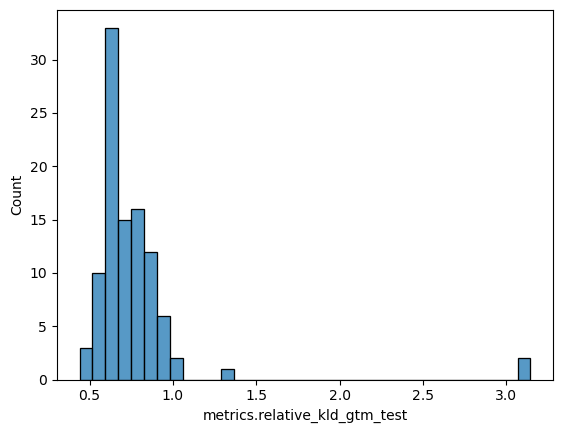

mean  0.7674890000000001
mode  0.69525


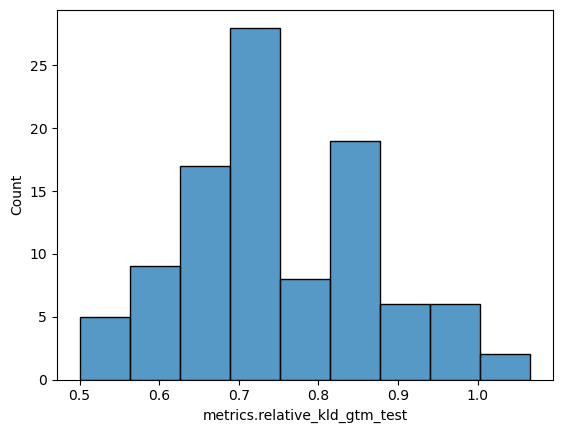

mean  0.7508410000000002
mode  0.74245


In [17]:
sns.histplot(data=df_runs_not_fixed_lasso_pen, x="metrics.relative_kld_gtm_test")
plt.show()

print("mean ", df_runs_not_fixed_lasso_pen["metrics.relative_kld_gtm_test"].mean())
print("mode ", df_runs_not_fixed_lasso_pen["metrics.relative_kld_gtm_test"].quantile(0.5))


sns.histplot(data=df_runs_fixed_lasso_pen, x="metrics.relative_kld_gtm_test")
plt.show()

print("mean ", df_runs_fixed_lasso_pen["metrics.relative_kld_gtm_test"].mean())
print("mode ", df_runs_fixed_lasso_pen["metrics.relative_kld_gtm_test"].quantile(0.5))

check out penalties chosen

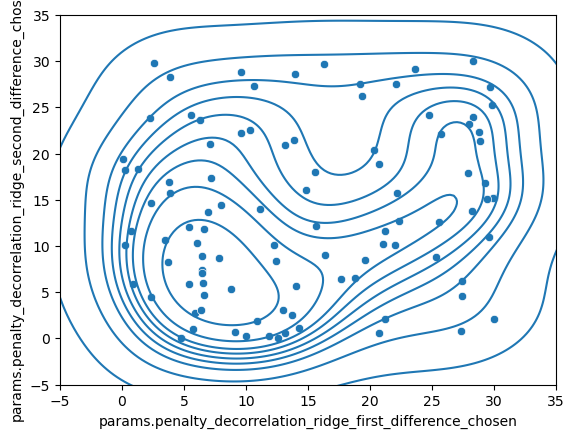

(-5.0, 35.0)

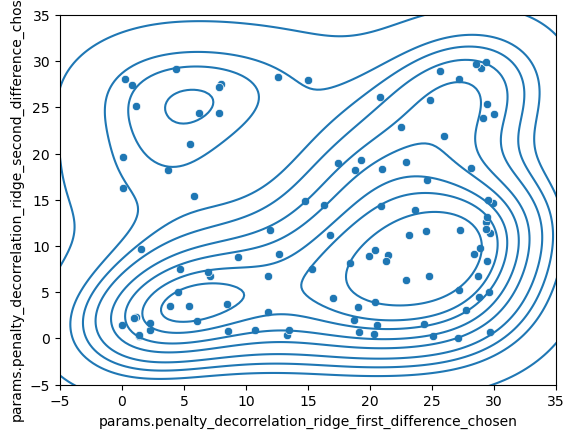

In [18]:
cols = [
    "params.penalty_decorrelation_ridge_first_difference_chosen",
    "params.penalty_decorrelation_ridge_second_difference_chosen",
]
df_runs_not_fixed_lasso_pen[cols] = df_runs_not_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
sns.scatterplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
plt.ylim(-5,35)
plt.xlim(-5,35)
plt.show()

cols = [
    "params.penalty_decorrelation_ridge_first_difference_chosen",
    "params.penalty_decorrelation_ridge_second_difference_chosen",
]
df_runs_fixed_lasso_pen[cols] = df_runs_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
sns.scatterplot(data=df_runs_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
plt.ylim(-5,35)
plt.xlim(-5,35)

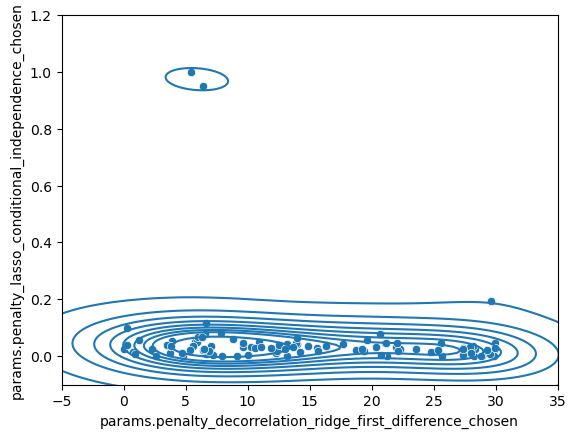

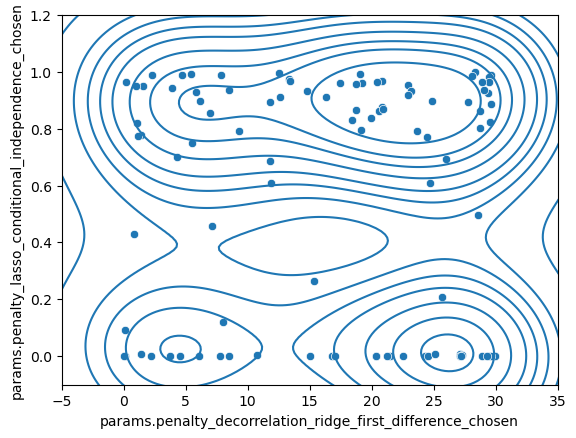

In [19]:
cols = [
    "params.penalty_decorrelation_ridge_first_difference_chosen",
    "params.penalty_lasso_conditional_independence_chosen",
]
df_runs_not_fixed_lasso_pen[cols] = df_runs_not_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_lasso_conditional_independence_chosen")
sns.scatterplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_lasso_conditional_independence_chosen")
plt.ylim(-0.1,1.2)
plt.xlim(-5,35)
plt.show()

cols = [
    "params.penalty_decorrelation_ridge_first_difference_chosen",
    "params.penalty_lasso_conditional_independence_chosen",
]
df_runs_fixed_lasso_pen[cols] = df_runs_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_lasso_conditional_independence_chosen")
sns.scatterplot(data=df_runs_fixed_lasso_pen, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_lasso_conditional_independence_chosen")
plt.ylim(-0.1,1.2)
plt.xlim(-5,35)
plt.show()

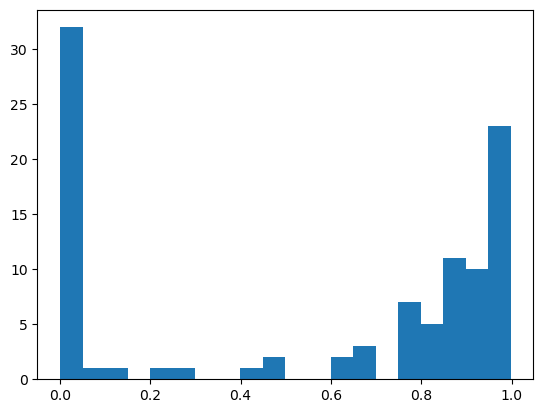

In [20]:
plt.hist(df_runs_fixed_lasso_pen["params.penalty_lasso_conditional_independence_chosen"].astype(float), bins=20)
plt.show()

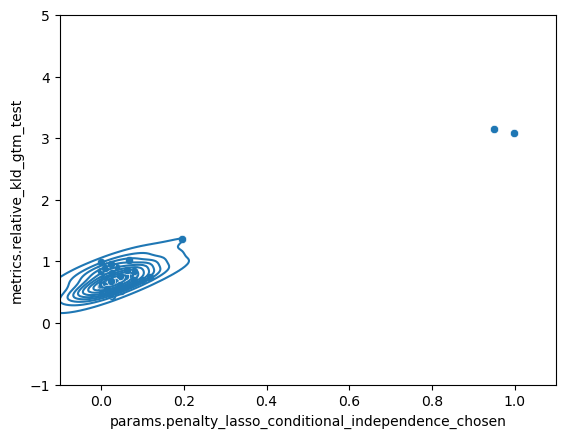

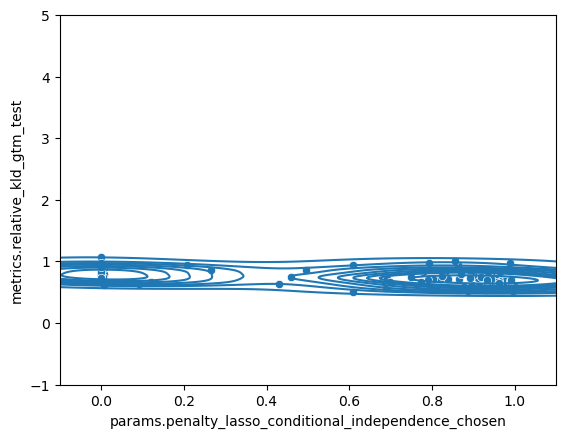

In [21]:
cols = [
    "params.penalty_lasso_conditional_independence_chosen",
    "metrics.relative_kld_gtm_test",
]
df_runs_not_fixed_lasso_pen[cols] = df_runs_not_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
sns.scatterplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
plt.ylim(-1,5)
plt.xlim(-0.1,1.1)
plt.show()


cols = [
    "params.penalty_lasso_conditional_independence_chosen",
    "metrics.relative_kld_gtm_test",
]
df_runs_fixed_lasso_pen[cols] = df_runs_fixed_lasso_pen[cols].astype(float)

sns.kdeplot(data=df_runs_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
sns.scatterplot(data=df_runs_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
plt.ylim(-1,5)
plt.xlim(-0.1,1.1)
plt.show()

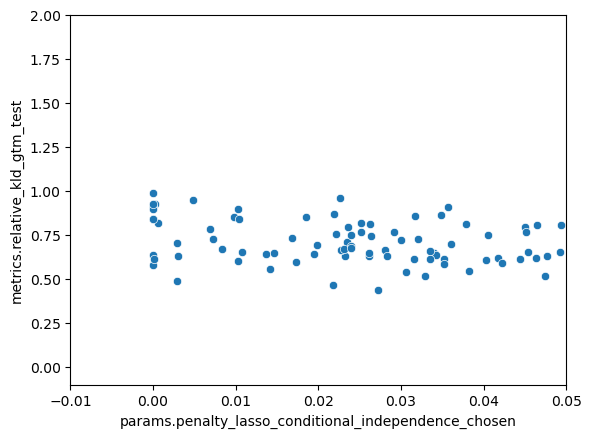

(-0.01, 1.1)

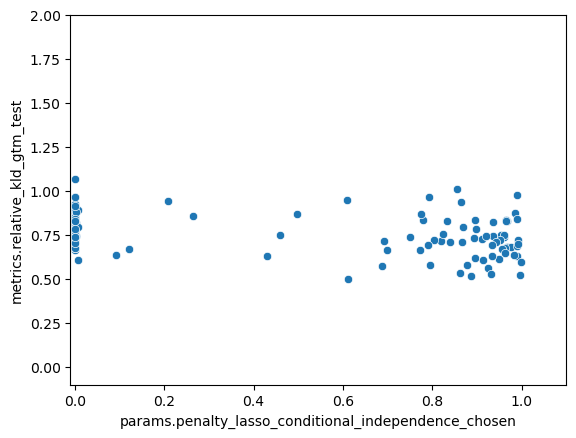

In [22]:
cols = [
    "params.penalty_lasso_conditional_independence_chosen",
    "metrics.relative_kld_gtm_test",
]
df_runs_not_fixed_lasso_pen[cols] = df_runs_not_fixed_lasso_pen[cols].astype(float)

#sns.kdeplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
sns.scatterplot(data=df_runs_not_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
plt.ylim(-0.1,2)
plt.xlim(-0.01,0.05)
plt.show()

cols = [
    "params.penalty_lasso_conditional_independence_chosen",
    "metrics.relative_kld_gtm_test",
]
df_runs_fixed_lasso_pen[cols] = df_runs_fixed_lasso_pen[cols].astype(float)

#sns.kdeplot(data=df_runs_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
sns.scatterplot(data=df_runs_fixed_lasso_pen, x="params.penalty_lasso_conditional_independence_chosen", y="metrics.relative_kld_gtm_test")
plt.ylim(-0.1,2)
plt.xlim(-0.01,1.1)